# Huấn luyện VAE bằng GPU Colab trong VS Code

Chọn kernel Colab GPU, chạy phần thiết lập và cell cấu hình chung, rồi chọn cell 6 (sanity check) hoặc cell 7 (train chính). Notebook gọi `models/vae/train.py`, hiển thị log từng epoch và lưu ZIP trên My Drive để bạn tải thủ công.

Để train trên máy, chạy `python models/vae/train.py` từ thư mục gốc project.

## 1. Xác nhận runtime GPU

Cell kiểm tra PyTorch trong tiến trình mới. Nếu chính tiến trình này báo lỗi khi import, hãy xem dòng lỗi cuối. Với Colab đã thay đổi thư viện, hãy lưu các tệp cần giữ trên Drive trước khi chọn **Disconnect and delete runtime** rồi kết nối GPU mới.

In [1]:
import subprocess
import sys

# Dùng đúng interpreter sẽ chạy train, trong một tiến trình Python mới.
def run_python(source, *args, cwd=None):
    result = subprocess.run(
        [sys.executable, "-u", "-c", source, *map(str, args)],
        cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True, errors="replace",
    )
    print(result.stdout, end="", flush=True)
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or f"Python kết thúc với mã {result.returncode}")

run_python("""
import sys
from importlib.metadata import version
print(f"Python {sys.version.split()[0]}, torch {version('torch')}", flush=True)
import torch
if not torch.cuda.is_available():
    raise RuntimeError("Chọn runtime GPU trong Colab rồi kết nối lại.")
gpu = torch.cuda.get_device_properties(0)
print(f"GPU: {gpu.name} | VRAM: {gpu.total_memory / 1024**3:.1f} GB")
""")

Python 3.13.16, torch 2.14.1+cu130
GPU: Tesla T4 | VRAM: 14.6 GB


## 2. Mount Drive và cấu hình dữ liệu

Checkpoint được lưu trên Google Drive. Dataset mặc định nằm trên SSD của VM. Đặt `PERSIST_DATA_ON_DRIVE = True` nếu muốn giữ dataset qua các lần khởi động runtime.

Nếu extension chưa mount được Drive từ cell, chạy **Colab: Mount Google Drive to Server…** trong Command Palette rồi chạy lại cell này.

In [3]:
import os
from pathlib import Path

PERSIST_DATA_ON_DRIVE = False
REPO_URL = 'https://github.com/lucaspham102/DL_ImgGenModel.git'
PROJECT_DIR = Path('/content/DL_ImgGenModel')

from google.colab import drive

my_drive = Path("/content/drive/MyDrive")
if not my_drive.is_dir():
    try:
        drive.mount("/content/drive")
    except Exception as exc:
        if 'FAILED_PRECONDITION' not in str(exc) and 'Precondition check failed' not in str(exc):
            raise
        raise RuntimeError(
            'Colab chưa xác thực được Google Drive. Trong VS Code, nhấn Ctrl+Shift+P, '
            'chọn Colab: Mount Google Drive to Server, cấp quyền rồi chạy lại mục 2. '
            'Trên Colab web, mở Files, chọn Mount Drive và hoàn tất cấp quyền.'
        ) from exc
if not my_drive.is_dir():
    raise FileNotFoundError(f"Không truy cập được My Drive tại {my_drive}")
STORAGE_ROOT = my_drive / "DL_ImgGenModel_storage"

CKPT_DIR = STORAGE_ROOT / 'checkpoints'
if PERSIST_DATA_ON_DRIVE:
    DATA_ROOT = STORAGE_ROOT / 'data'
    KAGGLE_CACHE = STORAGE_ROOT / 'kagglehub_cache'
else:
    DATA_ROOT = Path('/content/DL_ImgGenModel_runtime/data')
    KAGGLE_CACHE = Path('/content/kagglehub_cache')
for path in (DATA_ROOT, CKPT_DIR, KAGGLE_CACHE):
    path.mkdir(parents=True, exist_ok=True)

# Cache đi theo lựa chọn PERSIST_DATA_ON_DRIVE.
os.environ['KAGGLEHUB_CACHE'] = str(KAGGLE_CACHE)
print('Data:', DATA_ROOT)
print('Checkpoints:', CKPT_DIR)
print('Kaggle cache:', KAGGLE_CACHE)

Mounted at /content/drive
Data: /content/DL_ImgGenModel_runtime/data
Checkpoints: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints
Kaggle cache: /content/kagglehub_cache


## 3. Đồng bộ mã nguồn từ GitHub

In [5]:
import os
import subprocess
import sys

REPO_BRANCH = 'khanh'

def git(*args, cwd=None):
    result = subprocess.run(['git', *args], cwd=cwd, capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError(result.stderr.strip() or result.stdout.strip() or f'Git trả về mã {result.returncode}')
    return result.stdout.strip()

if (PROJECT_DIR / '.git').is_dir():
    changes = git('status', '--porcelain', cwd=PROJECT_DIR)
    if changes:
        print('Đang dùng mã nguồn đã chỉnh trên runtime:', changes, sep='\n')
    else:
        git('fetch', REPO_URL, REPO_BRANCH, cwd=PROJECT_DIR)
        git('switch', '--detach', 'FETCH_HEAD', cwd=PROJECT_DIR)
elif PROJECT_DIR.exists() and any(PROJECT_DIR.iterdir()):
    raise RuntimeError(f'{PROJECT_DIR} đã tồn tại nhưng không phải Git repository.')
else:
    git('clone', '--branch', REPO_BRANCH, REPO_URL, str(PROJECT_DIR))

train_script = PROJECT_DIR / 'models/vae/train.py'
if not train_script.is_file():
    raise FileNotFoundError(f'Thiếu script huấn luyện tại {train_script}.')

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
print('Commit nền của mã nguồn đang dùng:', git('log', '-1', '--oneline', cwd=PROJECT_DIR))

Commit nền của mã nguồn đang dùng: 15f1d64 chỉnh sửa test_smoke


## 4. Kiểm tra thư viện và CUDA

In [6]:
from importlib.util import find_spec

run_python("""
import torch
import torchvision
from data.dataloader import get_dataloaders
from models.vae import VAE
print(f"PyTorch {torch.__version__}, torchvision {torchvision.__version__}")
""", cwd=PROJECT_DIR)

def install_if_missing(package):
    if find_spec(package) is None:
        result = subprocess.run(
            [sys.executable, "-m", "pip", "install", package],
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
        )
        print(result.stdout)
        if result.returncode != 0:
            raise RuntimeError(f"pip không cài được {package}. Xem thông báo pip ở trên.")

PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130


## 5. Cấu hình W&B

Mặc định `BACKEND = 'none'`. Để ghi log lên W&B, đổi thành `'wandb'` và dùng secret `WANDB_API_KEY` hoặc đăng nhập khi được hỏi.

In [7]:
BACKEND = 'none'
WANDB_PROJECT = 'DL_ImageGenModel'
WANDB_ENTITY = '24022367-vietnam-national-university-hanoi'

if BACKEND == 'wandb':
    install_if_missing('wandb')
    import wandb
    api_key = None
    try:
        from google.colab import userdata
        api_key = userdata.get('WANDB_API_KEY')
    except Exception:
        pass
    wandb.login(key=api_key) if api_key else wandb.login()
    print('W&B đã đăng nhập.')

## 6. Sanity check VAE và trực quan hóa metric

Chạy cell cấu hình chung trước. Cell 6 train với 2.000 ảnh Fashion-MNIST trong 5 epoch. Cell 6 và 7 hiển thị bảng train/validation, ba biểu đồ loss và hai lưới ảnh từ checkpoint tốt nhất. Cuối cell có đường dẫn ZIP trong My Drive.

In [8]:
import os
import re
import subprocess
import sys
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

BATCH_SIZE = 64
LEARNING_RATE = 5e-4
LATENT_DIM = 128
KL_WEIGHT = 1.0
KL_WARMUP_EPOCHS = 10
SEED = 42
RESUME = True


def vae_paths():
    if not {"PROJECT_DIR", "DATA_ROOT", "CKPT_DIR"} <= globals().keys():
        raise RuntimeError("Chạy phần thiết lập Colab, Drive và mã nguồn trước.")
    return PROJECT_DIR, DATA_ROOT, CKPT_DIR


PREVIEW_SCRIPT = """
import sys
import torch
from torchvision.utils import save_image
from data.dataloader import denormalize, get_dataloaders
from models.vae.vae import VAE

dataset, data_root, checkpoint_path, reconstruction_path, generated_path, seed = sys.argv[1:]
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Load only a trusted training checkpoint. It includes NumPy/Python RNG state.
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
if 'models' in checkpoint:
    state_dict = checkpoint['models']['vae']
else:
    state_dict = checkpoint.get('model_state_dict', checkpoint.get('state_dict', checkpoint))

# Infer architecture from weights so it matches the selected checkpoint.
latent_dim = state_dict['encoder.fc_mu.weight'].shape[0]
model = VAE(in_channels=3, latent_dim=latent_dim).to(device)
model.load_state_dict(state_dict)
model.eval()
print(f'Checkpoint: {checkpoint_path} | Epoch: {checkpoint.get("epoch", "?")} | Latent dim: {latent_dim}')

# Reuse the official validation split and eval transforms.
_, val_loader, _ = get_dataloaders(
    name=dataset,
    root=str(data_root),
    batch_size=8, seed=int(seed),
    num_workers=0,
    validate_integrity=False,
)

with torch.inference_mode():
    real_images, _ = next(iter(val_loader))
    real_images = real_images.to(device)
    reconstructed_images = model.reconstruct(real_images)
    generated_images = model.sample(64)

    comparison = torch.cat([real_images, reconstructed_images])

save_image(denormalize(comparison.cpu(), clamp=True), reconstruction_path, nrow=len(real_images))
save_image(denormalize(generated_images.cpu(), clamp=True), generated_path, nrow=8)
"""


def save_vae_previews(project, data, dataset, best_path, run_dir, prefix):
    from IPython.display import Image, display

    recon = run_dir / f"{prefix}_reconstruction.png"
    generated = run_dir / f"{prefix}_generated.png"
    run_python(PREVIEW_SCRIPT, dataset, data, best_path, recon, generated, SEED, cwd=project)
    print("Ảnh thật (trên) và ảnh tái tạo (dưới)")
    display(Image(filename=str(recon)))
    print("Ảnh sinh từ nhiễu chuẩn")
    display(Image(filename=str(generated)))
    return recon, generated


def run_vae(run, dataset, epochs, *, subset=None):
    project, data, checkpoint_root = vae_paths()
    if not (project / "models" / "vae" / "train.py").is_file():
        raise FileNotFoundError(f"Không tìm thấy models/vae/train.py tại {project}")

    if dataset == "celeba":
        install_if_missing("kagglehub")

    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    from IPython.display import display

    run_dir = checkpoint_root / "sanity_local" if run == "sanity" else checkpoint_root
    run_dir.mkdir(parents=True, exist_ok=True)
    prefix = f"sanity_{dataset}" if run == "sanity" else f"vae_{dataset}_training"
    csv_path = run_dir / f"{prefix}_metrics.csv"
    png_path = run_dir / f"{prefix}_curves.png"
    log_path = run_dir / f"{prefix}.log"
    last_path = run_dir / f"vae_{dataset}_last.pt"
    best_path = run_dir / f"vae_{dataset}_best.pt"

    command = [
        sys.executable, "-u", "models/vae/train.py",
        "--dataset", dataset,
        "--data-root", str(data),
        "--ckpt-dir", str(run_dir),
        "--epochs", str(epochs),
        "--batch-size", str(BATCH_SIZE),
        "--lr", str(LEARNING_RATE),
        "--latent-dim", str(LATENT_DIM),
        "--kl-weight", str(KL_WEIGHT),
        "--kl-warmup-epochs", str(min(KL_WARMUP_EPOCHS, epochs)),
        "--seed", str(SEED),
        "--backend", globals().get("BACKEND", "none"),
        "--project", globals().get("WANDB_PROJECT", "DL_ImageGenModel"),
        "--entity", globals().get("WANDB_ENTITY", ""),
    ]
    if subset is not None:
        command.extend(["--subset", str(subset)])
    resumed = RESUME and last_path.is_file()
    if resumed:
        command.extend(["--resume", str(last_path)])
        print(f"Resume từ {last_path}", flush=True)

    epoch_pattern = re.compile(
        r"\[Epoch\s+(\d+)/\d+\s+-\s+[0-9.]+s\]\s+"
        r"Train Loss:\s+(\S+)\s+\(Recon:\s+(\S+),\s+KL:\s+(\S+)\)\s+\|\s+"
        r"Val Loss:\s+(\S+)\s+\(Recon:\s+(\S+),\s+KL:\s+(\S+)\)"
    )
    batch_pattern = re.compile(r"^Epoch \[\d+/\d+\] \| Batch")
    columns = ["Epoch", "Train Loss", "Train Recon", "Train KL", "Val Loss", "Val Recon", "Val KL"]
    rows = []
    with log_path.open("a" if resumed else "w", encoding="utf-8") as log, subprocess.Popen(
        command, cwd=project, env={**os.environ, "PYTHONIOENCODING": "utf-8"},
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, encoding="utf-8", errors="replace",
    ) as process:
        for line in process.stdout:
            log.write(line)
            log.flush()
            match = epoch_pattern.search(line)
            if match:
                epoch, *values = match.groups()
                rows.append([int(epoch), *map(float, values)])
            if not batch_pattern.match(line):
                print(line, end="", flush=True)
        return_code = process.wait()
    if return_code:
        raise subprocess.CalledProcessError(return_code, command)

    history = pd.DataFrame(rows, columns=columns)
    if resumed and csv_path.is_file():
        previous = pd.read_csv(csv_path)
        if not history.empty:
            previous = previous[previous["Epoch"] < history["Epoch"].min()]
        history = pd.concat([previous, history], ignore_index=True)
    if not resumed and history["Epoch"].tolist() != list(range(1, epochs + 1)):
        raise RuntimeError(f"Cần đủ metric từ epoch 1 đến {epochs}. Kiểm tra log huấn luyện.")
    if history.empty or history["Epoch"].max() < epochs:
        raise RuntimeError(f"Chưa có metric đến epoch {epochs}. Kiểm tra log hoặc tăng EPOCHS khi resume.")
    if not np.isfinite(history[columns[1:]].to_numpy(dtype=float)).all():
        raise RuntimeError("Metric chứa NaN hoặc Inf.")
    history = history.sort_values("Epoch")
    display(history.style.format({column: "{:.2f}" for column in columns[1:]}))
    history.to_csv(csv_path, index=False)

    figure, axes = plt.subplots(1, 3, figsize=(18, 5))
    for axis, title, metric in zip(axes, ["Total Loss", "Reconstruction", "KL Divergence"], ["Loss", "Recon", "KL"]):
        for split in ("Train", "Val"):
            axis.plot(history["Epoch"], history[f"{split} {metric}"], marker="o", label=split)
        axis.set(title=title, xlabel="Epoch", ylabel="Loss")
        axis.grid(alpha=0.3)
        axis.legend()
    figure.suptitle(f"VAE {dataset} · {run}")
    figure.tight_layout()
    figure.savefig(png_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    preview_paths = save_vae_previews(project, data, dataset, best_path, run_dir, prefix)
    print(f"Đã lưu checkpoint, log, CSV, biểu đồ và ảnh mẫu tại {run_dir}")

    archive_path = run_dir / f"vae_{run}_{dataset}.zip"
    temp_archive = archive_path.with_suffix(".zip.tmp")
    with ZipFile(temp_archive, "w", compression=ZIP_DEFLATED, compresslevel=1) as archive:
        for path in (best_path, last_path, csv_path, png_path, log_path, *preview_paths):
            archive.write(path, arcname=path.name)
    temp_archive.replace(archive_path)
    print("Tải ZIP trong Google Drive:", archive_path, flush=True)

[*] Thiết bị huấn luyện VAE: cuda (Tesla T4)
[*] Đang nạp dữ liệu 'fashion_mnist' từ '/content/DL_ImgGenModel_runtime/data'...

  0%|          | 0.00/26.4M [00:00<?, ?B/s]
  0%|          | 32.8k/26.4M [00:00<01:57, 225kB/s]
  0%|          | 65.5k/26.4M [00:00<01:58, 223kB/s]
  0%|          | 131k/26.4M [00:00<01:21, 324kB/s] 
  1%|          | 229k/26.4M [00:00<00:57, 459kB/s]
  2%|▏         | 459k/26.4M [00:00<00:30, 853kB/s]
  3%|▎         | 918k/26.4M [00:00<00:15, 1.62MB/s]
  6%|▌         | 1.64M/26.4M [00:01<00:09, 2.68MB/s]
 12%|█▏        | 3.24M/26.4M [00:01<00:04, 5.29MB/s]
 25%|██▍       | 6.49M/26.4M [00:01<00:01, 10.5MB/s]
 40%|████      | 10.6M/26.4M [00:01<00:01, 15.7MB/s]
 56%|█████▌    | 14.7M/26.4M [00:01<00:00, 19.4MB/s]
 71%|███████▏  | 18.9M/26.4M [00:01<00:00, 21.9MB/s]
 87%|████████▋ | 23.0M/26.4M [00:01<00:00, 23.6MB/s]
100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]

  0%|          | 0.00/29.5k [00:00<?, ?B/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 199kB/

,Epoch,Train Loss,Train Recon,Train KL,Val Loss,Val Recon,Val KL
0,1,4247.05,4183.75,316.53,2566.39,2234.51,331.88
1,2,1472.83,1385.10,219.35,1173.22,963.65,209.57
2,3,965.31,855.57,182.90,980.23,807.17,173.06
3,4,827.86,697.99,162.34,807.34,633.23,174.11
4,5,745.02,598.86,146.16,714.93,571.64,143.29


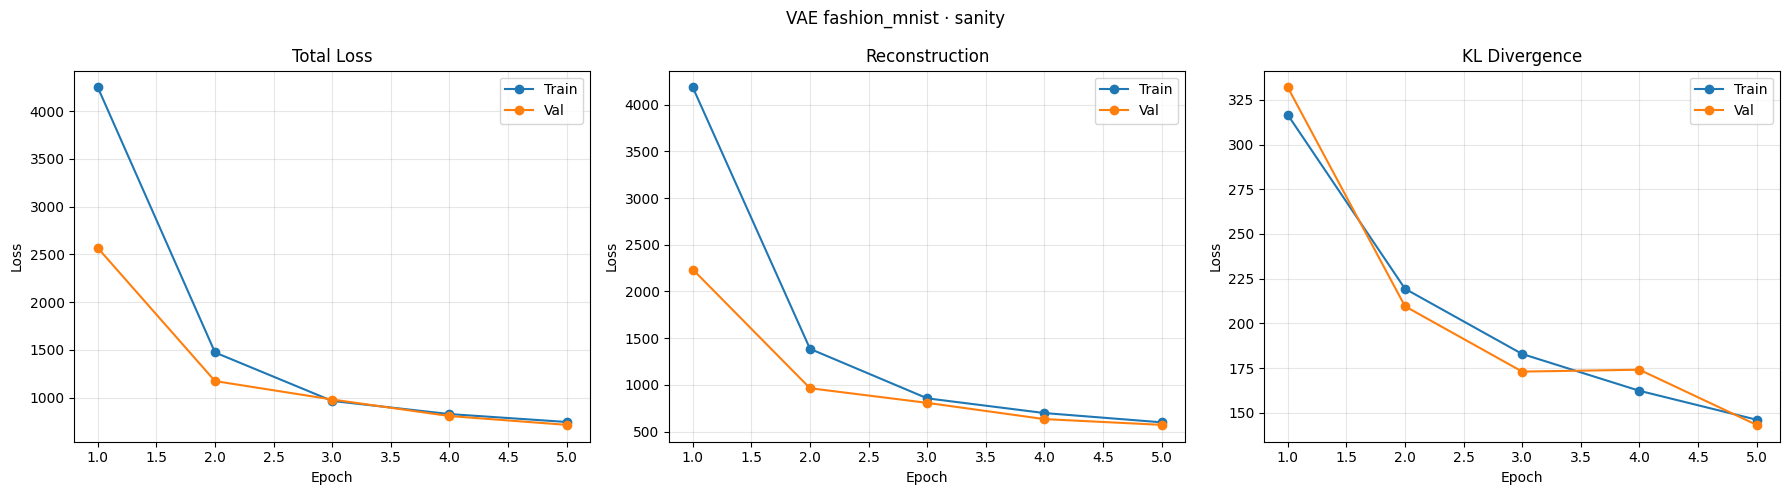

Checkpoint: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/sanity_local/vae_fashion_mnist_best.pt | Epoch: 5 | Latent dim: 128
Ảnh thật (trên) và ảnh tái tạo (dưới)


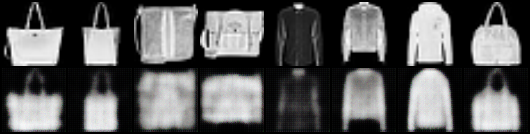

Ảnh sinh từ nhiễu chuẩn


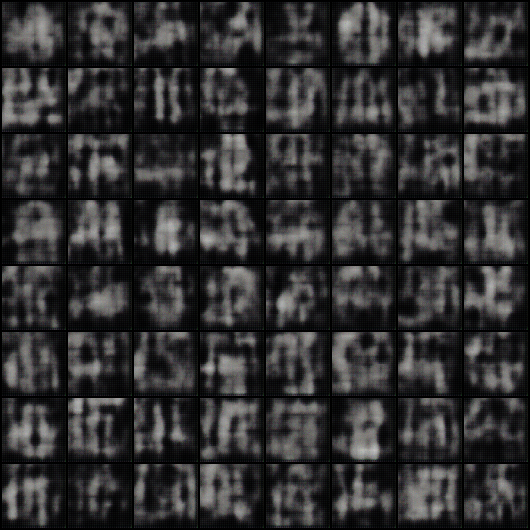

Đã lưu checkpoint, log, CSV, biểu đồ và ảnh mẫu tại /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/sanity_local
Tải ZIP trong Google Drive: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/sanity_local/vae_sanity_fashion_mnist.zip


In [9]:
run_vae("sanity", "fashion_mnist", epochs=5, subset=2000)

## 7. Huấn luyện VAE chính thức

Cell 7 huấn luyện trên toàn bộ tập train của dataset đã chọn. Đặt `DATASET = 'fashion_mnist'` nếu muốn chạy Fashion-MNIST. Cả hai cell dùng cấu hình chung, gồm `RESUME` để tiếp tục từ checkpoint đang có.

Cell hiển thị bảng Loss, Reconstruction và KL rồi lưu CSV và biểu đồ cùng checkpoint.

[*] Thiết bị huấn luyện VAE: cuda (Tesla T4)
[*] Đang nạp dữ liệu 'celeba' từ '/content/DL_ImgGenModel_runtime/data'...
[*] Chưa phát hiện ảnh CelebA. Đang tải từ Kaggle...
Using Colab cache for faster access to the 'celeba-dataset' dataset.
[+] CelebA nằm tại: /kaggle/input/celeba-dataset
[*] Đang quét và lập chỉ mục ảnh từ: '/kaggle/input/celeba-dataset'...
[+] Đã lập chỉ mục 202,599 ảnh trên đĩa.
[*] Đang đọc metadata phân chia chính thức: '/kaggle/input/celeba-dataset/list_eval_partition.csv'...
[*] Kiểm tra 202,599/202,599 ảnh...
[+] 202,599 ảnh đều hợp lệ.
[!] Không ghi được cache: [Errno 30] Read-only file system: '/kaggle/input/celeba-dataset/.celeba_validation_cache.json.tmp'
[+] Số ảnh CelebA trong mỗi tập:
    - Train (partition 0): 162,770 ảnh
    - Val   (partition 1): 19,867 ảnh
    - Test  (partition 2): 19,962 ảnh
[+] Dữ liệu sẵn sàng: 2543 batches train | 311 batches val

============================== BẮT ĐẦU HUẤN LUYỆN VAE (40 EPOCHS) ==============================
[

,Epoch,Train Loss,Train Recon,Train KL,Val Loss,Val Recon,Val KL
0,1,444.38,409.09,352.92,611.36,263.17,348.20
1,2,323.75,265.98,288.83,526.59,241.94,284.65
2,3,327.28,251.81,251.57,485.54,240.80,244.74
3,4,337.97,248.04,224.83,462.79,239.86,222.93
4,5,349.18,247.27,203.83,439.71,239.00,200.71
5,6,361.44,249.22,187.05,430.24,247.70,182.54
6,7,374.13,252.78,173.36,417.51,246.34,171.17
7,8,386.43,256.81,162.03,414.28,254.27,160.00
8,9,398.15,260.98,152.41,405.37,253.96,151.42
9,10,410.02,265.89,144.13,403.30,262.57,140.73


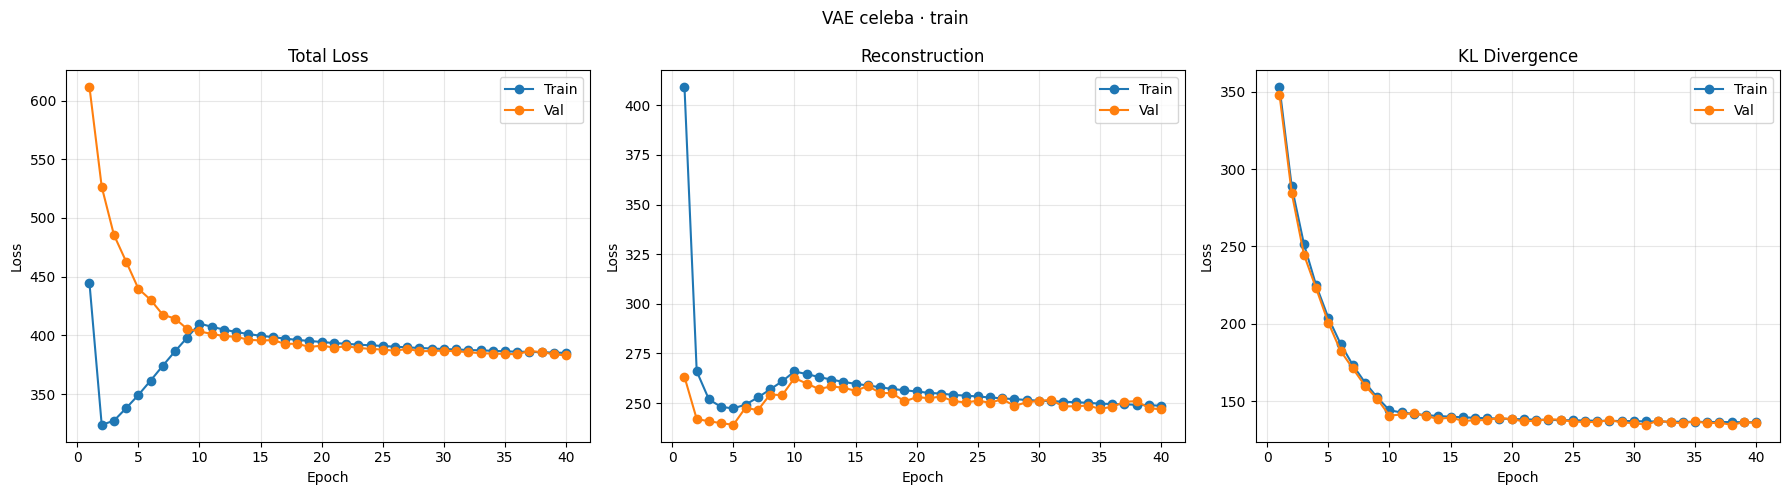

Checkpoint: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/vae_celeba_best.pt | Epoch: 40 | Latent dim: 128
[*] Chưa phát hiện ảnh CelebA. Đang tải từ Kaggle...
Using Colab cache for faster access to the 'celeba-dataset' dataset.
[+] CelebA nằm tại: /kaggle/input/celeba-dataset
[*] Đang quét và lập chỉ mục ảnh từ: '/kaggle/input/celeba-dataset'...
[+] Đã lập chỉ mục 202,599 ảnh trên đĩa.
[*] Đang đọc metadata phân chia chính thức: '/kaggle/input/celeba-dataset/list_eval_partition.csv'...
[+] Số ảnh CelebA trong mỗi tập:
    - Train (partition 0): 162,770 ảnh
    - Val   (partition 1): 19,867 ảnh
    - Test  (partition 2): 19,962 ảnh
Ảnh thật (trên) và ảnh tái tạo (dưới)


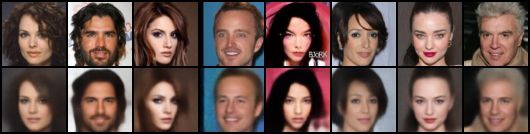

Ảnh sinh từ nhiễu chuẩn


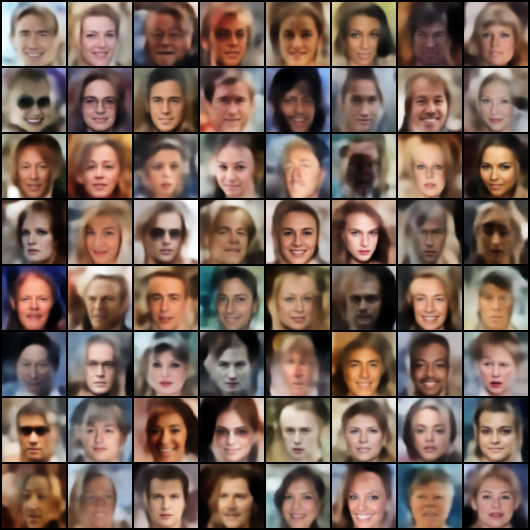

Đã lưu checkpoint, log, CSV, biểu đồ và ảnh mẫu tại /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints
Tải ZIP trong Google Drive: /content/drive/MyDrive/DL_ImgGenModel_storage/checkpoints/vae_train_celeba.zip


In [10]:
DATASET = "celeba"
EPOCHS = 40

run_vae("train", DATASET, epochs=EPOCHS)

## 8. Kiểm tra checkpoint đã lưu

In [ ]:
_, _, checkpoint_root = vae_paths()
checkpoints = sorted(checkpoint_root.rglob('vae_*.pt'))
if not checkpoints:
    raise FileNotFoundError(f'Không tìm thấy checkpoint trong {checkpoint_root}')
for checkpoint in checkpoints:
    print(f'{checkpoint.relative_to(checkpoint_root)}: {checkpoint.stat().st_size / 1024**2:.1f} MB')

## 9. Xem ảnh từ checkpoint VAE CelebA

Chạy sau phần thiết lập Colab và đồng bộ mã nguồn. Cell dùng checkpoint `vae_celeba_best.pt` có sẵn để hiển thị và lưu ảnh tái tạo cùng ảnh sinh.

In [ ]:
project, data, checkpoints = vae_paths()
best = checkpoints / "vae_celeba_best.pt"
if not best.is_file():
    raise FileNotFoundError(f"Không tìm thấy checkpoint CelebA tại {best}")
_ = save_vae_previews(project, data, "celeba", best, checkpoints, "vae_celeba")